In [1]:
from pathlib import Path
from argparse import Namespace
import copy
import hashlib
import json
import os
import pickle
import shutil
import subprocess
import sys
import tempfile
import time
import zipfile
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 140)
pd.set_option("display.width", 220)

ROOT = Path.cwd()

TRACE_ORIGIN = pd.Timestamp("2024-03-01 00:00:00")
PRIMARY_GPU = "A100-SXM4-80GB"
CAPACITY = 3456

Q_GRID = [0.50, 0.80, 0.90, 0.95, 0.99]
H_GRID = [1, 2, 4]

EVICTION_SLO = 0.10
REFERENCE_Q = 0.90
REFERENCE_H = 1

RUN_TRANSFER = True
RESUME = True


FORCE_WORKERS = None
WORKER_CAP = 6
RAM_PER_WORKER_GB = 3.0

OUT = ROOT / "outputs_fame_gpu_04b"
RUNS = ROOT / "fame_gpu_04b_runs"
CHECKPOINT_DIR = RUNS / "checkpoints"
BRANCH_DIR = RUNS / "branches"

for p in [OUT, RUNS, CHECKPOINT_DIR, BRANCH_DIR]:
    p.mkdir(parents=True, exist_ok=True)

def choose_workers():
    logical = os.cpu_count() or 2

    try:
        import psutil
        physical = psutil.cpu_count(logical=False) or max(1, logical//2)
        available_gb = psutil.virtual_memory().available/(1024**3)

        cpu_limit = max(1, physical-1)
        ram_limit = max(1, int(available_gb//RAM_PER_WORKER_GB))

        workers = min(WORKER_CAP, cpu_limit, ram_limit)

        info = {
            "logical_cpus": logical,
            "physical_cpus": physical,
            "available_ram_gb": round(available_gb,2),
            "cpu_limit": cpu_limit,
            "ram_limit": ram_limit,
        }

    except Exception:
        workers = min(WORKER_CAP, max(1,logical//2))
        info = {
            "logical_cpus": logical,
            "physical_cpus": None,
            "available_ram_gb": None,
        }

    if FORCE_WORKERS is not None:
        workers = max(1,int(FORCE_WORKERS))

    return workers, info

MAX_WORKERS, PARALLEL_INFO = choose_workers()

print("MAX_WORKERS:",MAX_WORKERS)
print("PARALLEL_INFO:",PARALLEL_INFO)

MAX_WORKERS: 6
PARALLEL_INFO: {'logical_cpus': 20, 'physical_cpus': 12, 'available_ram_gb': 44.92, 'cpu_limit': 11, 'ram_limit': 14}


In [2]:
def locate_folder_or_zip(folder_name):
    for p in [ROOT/folder_name, Path("/mnt/data")/folder_name]:
        if p.exists() and p.is_dir():
            return p

    for zp in [ROOT/f"{folder_name}.zip", Path("/mnt/data")/f"{folder_name}.zip"]:
        if zp.exists():
            target = ROOT/f"{folder_name}_04b_extract"
            target.mkdir(exist_ok=True)

            with zipfile.ZipFile(zp) as z:
                z.extractall(target)

            p = target/folder_name
            if p.exists():
                return p

    raise FileNotFoundError(
        f"{folder_name}(.zip) não encontrado."
    )

OUT1 = locate_folder_or_zip("outputs_fame_gpu")
OUT3B = locate_folder_or_zip("outputs_fame_gpu_03b")
OUT4A = locate_folder_or_zip("outputs_fame_gpu_04a_v3_parallel")

windows = pd.read_csv(
    OUT1/"fame_windows_7d.csv",
    parse_dates=[
        "D_start","D_end_exclusive",
        "C_start","C_end_exclusive",
        "E_start","E_end_exclusive"
    ]
)

quota_long = pd.read_csv(
    OUT3B/"candidate_quota_long.csv.gz",
    compression="gzip",
    parse_dates=["origin"]
)

predictive_transfer = pd.read_csv(
    OUT3B/"physical_predictive_transfer.csv"
)

calibration = pd.read_csv(
    OUT4A/"calibration_candidate_results.csv"
)

calib_diag = pd.read_csv(
    OUT4A/"calibration_diagnostics.csv"
)

selected_C = pd.read_csv(
    OUT4A/"doc_selected_C.csv"
)

eligibility = pd.read_csv(
    OUT4A/"replication_eligibility.csv"
)

display(selected_C[
    ["replication","q","H","allocation_rate","eviction_rate","utility"]
])

,replication,q,H,allocation_rate,eviction_rate,utility
0,R04,0.90,1,0.752675,0.000000,0.752675
1,R05,0.95,1,0.903924,0.002488,0.903924
2,R06,0.80,4,0.923889,0.002806,0.923889
3,R07,0.90,4,0.785112,0.000308,0.785112
4,R08,0.90,2,0.856691,0.005488,0.856691
5,R09,0.90,2,0.919637,0.008099,0.919637


In [3]:
SCREEN_INACTIVE = eligibility.loc[
    ~eligibility["decision_active_C"],
    "replication"
].tolist()

BOUNDARY_DIAGNOSTIC = calib_diag.loc[
    ~calib_diag["surface_identified"],
    "replication"
].tolist()

PRINCIPAL_REPS = calib_diag.loc[
    calib_diag["surface_identified"],
    "replication"
].tolist()

ALL_TRANSFER_REPS = calib_diag["replication"].tolist()

print("Pre-screen decision-inactive:",SCREEN_INACTIVE)
print("Boundary diagnostic:",BOUNDARY_DIAGNOSTIC)
print("Principal transfer reps:",PRINCIPAL_REPS)
print("All simulated transfer reps:",ALL_TRANSFER_REPS)

classification = pd.DataFrame({
    "replication": windows["replication"]
})

classification["role"] = "not_used"

classification.loc[
    classification["replication"].isin(SCREEN_INACTIVE),
    "role"
] = "pre_screen_decision_inactive"

classification.loc[
    classification["replication"].isin(BOUNDARY_DIAGNOSTIC),
    "role"
] = "boundary_flat_C_surface"

classification.loc[
    classification["replication"].isin(PRINCIPAL_REPS),
    "role"
] = "principal_transfer"

display(classification)
classification.to_csv(
    OUT/"replication_roles.csv",
    index=False
)

Pre-screen decision-inactive: ['R01', 'R02', 'R03']
Boundary diagnostic: ['R04']
Principal transfer reps: ['R05', 'R06', 'R07', 'R08', 'R09']
All simulated transfer reps: ['R04', 'R05', 'R06', 'R07', 'R08', 'R09']


,replication,role
0,R01,pre_screen_decision_inactive
1,R02,pre_screen_decision_inactive
2,R03,pre_screen_decision_inactive
3,R04,boundary_flat_C_surface
4,R05,principal_transfer
5,R06,principal_transfer
6,R07,principal_transfer
7,R08,principal_transfer
8,R09,principal_transfer


In [4]:
ident_rows = []

for rep,g in calibration.groupby("replication"):
    g = g[g["status"]=="ok"].copy()
    g = g.sort_values(
        ["allocation_rate","eviction_rate"],
        ascending=[False,True]
    )

    best = g.iloc[0]
    second = g.iloc[1]

    gap = best["allocation_rate"] - second["allocation_rate"]

    ident_rows.append({
        "replication":rep,
        "best_q":best["q"],
        "best_H":best["H"],
        "allocation_top_gap":gap,
        "allocation_top_gap_gpu_hours":gap*CAPACITY*168,
        "allocation_surface_range":(
            g["allocation_rate"].max()-g["allocation_rate"].min()
        ),
        "allocation_surface_range_gpu_hours":(
            g["allocation_rate"].max()-g["allocation_rate"].min()
        )*CAPACITY*168,
        "eviction_surface_range":(
            g["eviction_rate"].max()-g["eviction_rate"].min()
        ),
        "weak_top_separation_lt_1_GPU_hour":bool(
            gap*CAPACITY*168 < 1
        ),
    })

identification = pd.DataFrame(ident_rows)
display(identification)

identification.to_csv(
    OUT/"calibration_identification_strength.csv",
    index=False
)

,replication,best_q,best_H,allocation_top_gap,allocation_top_gap_gpu_hours,allocation_surface_range,allocation_surface_range_gpu_hours,eviction_surface_range,weak_top_separation_lt_1_GPU_hour
0,R04,0.50,2,0.000000e+00,0.000000,0.000000,0.000000,0.000000,True
1,R05,0.95,1,7.463441e-07,0.433333,0.005779,3355.216667,0.000992,True
2,R06,0.80,4,1.563304e-04,90.766667,0.010809,6275.716667,0.006196,False
3,R07,0.90,4,2.296443e-07,0.133333,0.001124,652.433333,0.003744,True
4,R08,0.90,2,8.427947e-05,48.933333,0.008303,4820.566667,0.009676,False
5,R09,0.90,2,8.172467e-05,47.450000,0.001785,1036.633333,0.017100,False


In [5]:
DATA_DIR = None

for p in [ROOT/"data_fame_gpu", Path("/mnt/data")/"data_fame_gpu"]:
    if (p/"job_info_df.csv").exists():
        DATA_DIR = p
        break

if DATA_DIR is None:
    raise FileNotFoundError("Pasta data_fame_gpu não encontrada.")

jobs = pd.read_csv(DATA_DIR/"job_info_df.csv")
nodes = pd.read_csv(DATA_DIR/"node_info_df.csv")

a100_jobs = jobs[jobs["gpu_model"]==PRIMARY_GPU].copy()
a100_nodes = nodes[nodes["gpu_model"]==PRIMARY_GPU].copy()

a100_jobs["submit_time"] = pd.to_numeric(
    a100_jobs["submit_time"],
    errors="coerce"
)

a100_jobs["duration"] = pd.to_numeric(
    a100_jobs["duration"],
    errors="coerce"
)

hp_jobs = a100_jobs[a100_jobs["job_type"]=="HP"].copy()
spot_jobs = a100_jobs[a100_jobs["job_type"]=="Spot"].copy()

BASE_DATA = RUNS/"hp_only_data"
BASE_DATA.mkdir(exist_ok=True)

hp_jobs.to_csv(
    BASE_DATA/"job_info_df.csv",
    index=False
)

a100_nodes.to_csv(
    BASE_DATA/"node_info_df.csv",
    index=False
)

print("HP jobs:",len(hp_jobs))
print("Spot jobs:",len(spot_jobs))

HP jobs: 137396
Spot jobs: 31624


In [6]:
GFS_ORIGINAL = ROOT/"26ASPLOS-Spot"

if not GFS_ORIGINAL.exists():
    proc = subprocess.run(
        [
            "git","clone","--depth","1",
            "https://github.com/MachineLearningSystem/26ASPLOS-Spot.git",
            str(GFS_ORIGINAL)
        ],
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    print(proc.stdout)

    if proc.returncode != 0:
        raise RuntimeError("Falha ao obter 26ASPLOS-Spot.")

WORK_BASE = Path(
    tempfile.mkdtemp(prefix="fame_gpu_04b_")
)

GFS_FAME = WORK_BASE/"26ASPLOS-Spot-FAME"

shutil.copytree(
    GFS_ORIGINAL,
    GFS_FAME,
    ignore=shutil.ignore_patterns(
        ".git",
        "__pycache__",
        "*.pyc",
        ".pytest_cache"
    )
)

print("GFS_FAME:",GFS_FAME)

GFS_FAME: C:\Users\tiago\AppData\Local\Temp\fame_gpu_04b_imh0i5tv\26ASPLOS-Spot-FAME


In [7]:
fame_policy_code = r"""
import pandas as pd

from .spot import SpotScheduler


class SilentLogger:
    def info(self, *args, **kwargs):
        return None
    def warning(self, *args, **kwargs):
        return None
    def error(self, *args, **kwargs):
        return None


class _NoOpEstimator:
    def train(self, *args, **kwargs):
        return None


class FAMEQuotaScheduler(SpotScheduler):

    def __init__(self, trace, cluster, args, log_dir, logger=None):
        if logger is None:
            logger = SilentLogger()

        super(FAMEQuotaScheduler, self).__init__(
            trace,
            cluster,
            args,
            log_dir,
            logger
        )

        self._name = "fame_quota"
        self.estimator = _NoOpEstimator()
        self.prev_index = 0
        self._quota_lookup = {}
        self._last_quota = {}

    def set_quota_lookup(self, lookup):
        self._quota_lookup = lookup
        self._last_quota = {}

    def update_spot_quota(self, org_request_df, now_timestamp):
        for vc_name in self.cluster.vc_dict:
            key = (int(self.time), str(vc_name))

            if key in self._quota_lookup:
                quota = self._quota_lookup[key]
                self._last_quota[vc_name] = quota
            elif vc_name in self._last_quota:
                quota = self._last_quota[vc_name]
            else:
                quota = 0.0

            capacity = self.cluster.vc_dict[vc_name].total_gpus
            quota = max(
                0.0,
                min(float(quota),float(capacity))
            )

            self.spot_quota[vc_name]["quota"][1] = quota

            self.spot_quota_record.append(
                [now_timestamp,vc_name,1,quota,1.0]
            )

    def simulate_until(self, stop_time, record=False):
        stop_time = int(stop_time)
        prev_index = int(getattr(self,"prev_index",0))

        while self.time < stop_time:

            if self.time % 300 == 0:
                if (
                    record
                    and self.args.log_range[0]
                    <= self.time
                    <= self.args.log_range[1]
                ):
                    now_timestamp = (
                        pd.Timestamp(self.args.trace_range[0])
                        + pd.Timedelta(seconds=self.time)
                    )

                    self.update_spot_quota(
                        None,
                        now_timestamp
                    )

                if record:
                    for vc_name in self.guar_que_list:
                        vc = self.cluster.vc_dict[vc_name]
                        vc.update_eviction_score(self.time)

            # release
            for vc_name in self.run_list:
                run_ls = self.run_list[vc_name].copy()
                vc = self.cluster.vc_dict[vc_name]

                for job in run_ls:
                    if (
                        job["type"]=="Spot"
                        and self.time-job.get_ckpt_time()
                        >= job["spot_duration"]
                    ):
                        self.record_spot_succeed(job)
                        job.set_ckpt_time(self.time)

                    if job["remain"]==0:
                        job["status"]="end"
                        job["end_time"]=self.time
                        self.end_job_num += 1

                        assert vc.release_resource(job)

                        self.run_list[vc_name].remove(job)

                        self.gpu_request_dict[
                            vc_name
                        ][job["type"]] -= job["gpu_request"]

                        if job["type"]=="Spot":
                            self.record_spot_succeed(job)
                        else:
                            self.guar_request_dict[
                                job["org_key"]
                            ] -= job["gpu_request"]

                    else:
                        job["remain"] -= 1

            # pend newly submitted
            for idx in range(prev_index,self.total_job_num):
                job = self.trace.job_list[idx]

                if job["submit_time"] <= self.time:
                    self.pend_job(job)
                    prev_index = idx+1
                else:
                    prev_index = idx
                    break

            self.prev_index = prev_index

            # HP queue
            for vc_name in self.guar_que_list:
                self.guar_que_list[vc_name].sort(
                    key=lambda x:(
                        -x.__getitem__("gpu_request"),
                        x.__getitem__("submit_time")
                    )
                )

                que_ls = self.guar_que_list[vc_name].copy()
                failed_gpu_num = 16

                for job in que_ls:
                    if job["gpu_request"] >= failed_gpu_num:
                        continue

                    if self.job_placer(job):
                        self.run_guar(job)

                    elif self.time >= self.args.log_range[0]:
                        place_flag,preempt_jobs = (
                            self.place_with_preemption(job)
                        )

                        if place_flag:
                            self.run_guar(job)
                            self.preempt(job,preempt_jobs)
                        else:
                            failed_gpu_num = job["gpu_request"]

                    else:
                        failed_gpu_num = job["gpu_request"]

            # Spot queue
            for key in self.spot_que_list:
                self.spot_que_list[key].sort(
                    key=lambda x:(
                        -x.__getitem__("gpu_request"),
                        x.__getitem__("worker_num"),
                        x.__getitem__("submit_time")
                    )
                )

                spot_que_ls = self.spot_que_list[key].copy()
                failed_gpu_num = 16

                for job in spot_que_ls:
                    if job["gpu_request"] >= failed_gpu_num:
                        continue

                    allowed = (
                        self.time > self.args.log_range[1]
                        or (
                            self.args.log_range[0]
                            <= self.time
                            <= self.args.log_range[1]
                            and (
                                self.gpu_request_dict[key]["Spot"]
                                + job["gpu_request"]*job["worker_num"]
                                <= self.spot_quota[key]["quota"][
                                    job["guarantee_request"]
                                ]
                            )
                        )
                    )

                    if allowed:
                        if self.job_placer(job):
                            self.run_spot(job)
                        else:
                            self.cluster.vc_dict[
                                key
                            ].release_resource(job)

                            job.update({"nodes":[]})
                            failed_gpu_num = job["gpu_request"]

            if record and self.time % 60 == 0:
                self.recorder.update_seq_recorder()

            if (
                record
                and self.args.log_range[0]
                <= self.time
                <= self.args.log_range[1]
            ):
                self.update_guar_gpu_time()

            self.time += 1

        self.prev_index = prev_index
        return True
"""

(GFS_FAME/"policy"/"fame_quota.py").write_text(
    fame_policy_code,
    encoding="utf-8"
)

7600

In [8]:
def replace_once(path,old,new,label):
    txt = path.read_text(encoding="utf-8")

    if old not in txt:
        raise RuntimeError(
            f"Patch não encontrado: {label}"
        )

    path.write_text(
        txt.replace(old,new,1),
        encoding="utf-8"
    )


spot_path = GFS_FAME/"policy"/"spot.py"
spot_txt = spot_path.read_text(encoding="utf-8")

spot_txt = spot_txt.replace(
    "from estimator.gpu_request_estimator import GPURequestEstimator\n",
    ""
)

spot_txt = spot_txt.replace(
    "self.estimator = GPURequestEstimator(args)",
    "self.estimator = None"
)

spot_path.write_text(
    spot_txt,
    encoding="utf-8"
)


(GFS_FAME/"policy"/"__init__.py").write_text(
    "from .fame_quota import FAMEQuotaScheduler, SilentLogger\n",
    encoding="utf-8"
)


policy_path = GFS_FAME/"policy"/"policy.py"

replace_once(
    policy_path,
    'if self.args.scheduler == "spot_scheduler":',
    'if self.args.scheduler in ["spot_scheduler", "fame_quota"]:',
    "Spot placer"
)


utils_path = GFS_FAME/"utils.py"
utils_txt = utils_path.read_text(encoding="utf-8")

imp0 = utils_txt.find("from policy import (")

if imp0 != -1:
    imp1 = utils_txt.find(")\n",imp0)

    if imp1 == -1:
        raise RuntimeError(
            "Fim do import policy não localizado."
        )

    utils_txt = (
        utils_txt[:imp0]
        + "from policy import FAMEQuotaScheduler\n"
        + utils_txt[imp1+2:]
    )

sim0 = utils_txt.find("def simulate_vc(")
trace0 = utils_txt.find("# 任务trace数据",sim0)

if sim0 != -1 and trace0 != -1:
    utils_txt = (
        utils_txt[:sim0]
        + utils_txt[trace0:]
    )

utils_path.write_text(
    utils_txt,
    encoding="utf-8"
)


for p in [
    GFS_FAME/"policy"/"fame_quota.py",
    GFS_FAME/"policy"/"spot.py",
    GFS_FAME/"policy"/"policy.py",
    GFS_FAME/"utils.py",
]:
    proc = subprocess.run(
        [sys.executable,"-m","py_compile",str(p)],
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    if proc.returncode != 0:
        raise RuntimeError(
            f"{p.name}: {proc.stdout}"
        )

print("Patches OK.")

Patches OK.


In [9]:
for mod in list(sys.modules):
    if (
        mod=="utils"
        or mod=="cluster"
        or mod=="job"
        or mod=="policy"
        or mod.startswith("policy.")
    ):
        del sys.modules[mod]

sys.path.insert(0,str(GFS_FAME))

import utils
import cluster as gfs_cluster

from job import Job
from policy.fame_quota import (
    FAMEQuotaScheduler,
    SilentLogger
)
from policy.recorder.recorder import Recorder

print("Imports OK.")

Imports OK.


In [10]:
transfer_windows = windows[
    windows["replication"].isin(
        ALL_TRANSFER_REPS
    )
].copy()

last_E_end = transfer_windows[
    "E_end_exclusive"
].max()

date_range = (
    str(TRACE_ORIGIN),
    str(last_E_end-pd.Timedelta(seconds=1))
)

base_df = utils.trace_process(
    str(BASE_DATA),
    date_range,
    (10**12,10**12+1)
)

def sec(ts):
    return int(
        (pd.Timestamp(ts)-TRACE_ORIGIN)
        .total_seconds()
    )

base_args = Namespace(
    scheduler="fame_quota",
    log_range=(10**12,10**12+1),
    trace_range=(str(TRACE_ORIGIN),str(last_E_end)),
    guarantee_hour=[1],
    guarantee_rate=.90,
    pred_len=4,
    ckpt_interval=300,
    use_gpu=False,
)

def build_fresh_base():
    bt = utils.trace_parser(
        base_df.copy()
    )

    bc = gfs_cluster.Cluster(
        str(BASE_DATA/"node_info_df.csv")
    )

    return FAMEQuotaScheduler(
        bt,
        bc,
        copy.deepcopy(base_args),
        str(RUNS/"base"),
        SilentLogger()
    )

def checkpoint_path_for(rep):
    return CHECKPOINT_DIR/f"{rep}_Cstart_HP.pkl"

def save_checkpoint(scheduler,path):
    scheduler.logger = SilentLogger()

    scheduler.recorder = Recorder(
        scheduler,
        str(CHECKPOINT_DIR)
    )

    scheduler.recorder.logger = scheduler.logger

    with open(path,"wb") as f:
        pickle.dump(
            scheduler,
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )

    with open(path,"rb") as f:
        test=pickle.load(f)

    assert test.time==scheduler.time

    return path.stat().st_size

base_scheduler = build_fresh_base()

checkpoint_runtime=[]

for rep in ALL_TRANSFER_REPS:
    wr=transfer_windows[
        transfer_windows["replication"]==rep
    ].iloc[0]

    target=sec(wr["C_start"])
    cp=checkpoint_path_for(rep)

    if cp.exists():
        try:
            with open(cp,"rb") as f:
                test=pickle.load(f)

            if test.time==target:
                print("CHECKPOINT OK/SKIP",rep)
                base_scheduler=test
                continue
        except Exception:
            pass

    if base_scheduler.time > target:
        base_scheduler=build_fresh_base()

    t0=time.time()

    base_scheduler.simulate_until(
        target,
        record=False
    )

    elapsed=time.time()-t0

    size=save_checkpoint(
        base_scheduler,
        cp
    )

    checkpoint_runtime.append({
        "replication":rep,
        "warmup_increment_s":elapsed,
        "checkpoint_MB":size/1024**2,
    })

    print(
        rep,
        "| warm-up incremental",
        round(elapsed/60,2),
        "min"
    )

pd.DataFrame(
    checkpoint_runtime
).to_csv(
    OUT/"checkpoint_runtime.csv",
    index=False
)

C:\Users\tiago\AppData\Local\Temp\fame_gpu_04b_imh0i5tv\26ASPLOS-Spot-FAME\utils.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(


CHECKPOINT OK/SKIP R04
CHECKPOINT OK/SKIP R05
CHECKPOINT OK/SKIP R06
CHECKPOINT OK/SKIP R07
CHECKPOINT OK/SKIP R08
CHECKPOINT OK/SKIP R09


In [11]:
grid = pd.MultiIndex.from_product(
    [Q_GRID,H_GRID],
    names=["q","H"]
).to_frame(index=False)

def period_row(rep):
    return windows[
        windows["replication"]==rep
    ].iloc[0]

def candidate_hourly(rep,period,q,H):
    z=quota_long[
        (quota_long["replication"]==rep)
        & (quota_long["period"]==period)
        & np.isclose(quota_long["q"],q)
        & (quota_long["H"]==H)
    ].copy()

    return z[["origin","quota"]].sort_values("origin")

def combined_5min(rep,q,H):
    frames=[]

    for period in ["C","E"]:
        h=candidate_hourly(
            rep,period,q,H
        )

        rows=[]

        for r in h.itertuples(index=False):
            for minute in range(0,60,5):
                ts=(
                    pd.Timestamp(r.origin)
                    + pd.Timedelta(minutes=minute)
                )

                rows.append({
                    "time":sec(ts),
                    "vc_name":PRIMARY_GPU,
                    "quota":float(
                        np.clip(r.quota,0,CAPACITY)
                    ),
                    "period":period,
                })

        frames.append(pd.DataFrame(rows))

    return pd.concat(
        frames,
        ignore_index=True
    )

test=combined_5min(
    ALL_TRANSFER_REPS[0],
    .90,
    1
)

display(test.groupby("period").size())

period
C    2016
E    2016
dtype: int64

In [12]:
worker_source = r"""
from pathlib import Path
import argparse
import json
import pickle
import sys

import numpy as np
import pandas as pd


def summarize_segment(sched, recorder_df, spot_jobs, hp_jobs):
    if len(recorder_df)==0:
        raise RuntimeError("Recorder vazio.")

    allocation = (
        (
            recorder_df["total_gpu_num"]
            - recorder_df["idle_gpu_num"]
        )
        / recorder_df["total_gpu_num"]
    )

    vc_name = next(
        iter(sched.cluster.vc_dict.keys())
    )

    failed=float(
        sched.spot_failed[vc_name]
    )

    succeed=float(
        sched.spot_succeed[vc_name]
    )

    eviction=(
        failed/(failed+succeed)
        if failed+succeed>0
        else 0.0
    )

    spot_started=[
        j for j in spot_jobs
        if j.get("status") in {"run","end"}
    ]

    hp_started=[
        j for j in hp_jobs
        if j.get("status") in {"run","end"}
    ]

    return {
        "allocation_rate":float(allocation.mean()),
        "allocation_rate_min":float(allocation.min()),
        "allocation_rate_max":float(allocation.max()),

        "native_spot_failed":failed,
        "native_spot_succeed":succeed,
        "eviction_rate":float(eviction),

        "mean_HP_queue_jobs":float(
            recorder_df["guar_que_job_num"].mean()
        ),

        "max_HP_queue_jobs":float(
            recorder_df["guar_que_job_num"].max()
        ),

        "mean_Spot_queue_jobs":float(
            recorder_df["spot_que_job_num"].mean()
        ),

        "max_Spot_queue_jobs":float(
            recorder_df["spot_que_job_num"].max()
        ),

        "guar_useful_gpu_time_rate":float(
            sum(sched.guar_gpu_time.values())
            /(sched.timespan*sched.cluster.total_gpus)
        ),

        "spot_useful_gpu_time_rate":float(
            sum(sched.spot_gpu_time.values())
            /(sched.timespan*sched.cluster.total_gpus)
        ),

        "n_HP_submitted":len(hp_jobs),
        "n_Spot_submitted":len(spot_jobs),
        "n_HP_started_by_segment_end":len(hp_started),
        "n_Spot_started_by_segment_end":len(spot_started),
    }


def reset_segment_metrics(sched, out_dir):
    # Import LOCAL: evita qualquer problema de escopo em subprocessos.
    from policy.recorder.recorder import Recorder

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    sched.spot_failed = sched.init_count_dict()
    sched.spot_succeed = sched.init_count_dict()
    sched.preemption_times = 0
    sched.spot_quota_record = []
    sched.guar_gpu_time = sched.init_count_dict()
    sched.spot_gpu_time = sched.init_count_dict()

    sched.recorder = Recorder(
        sched,
        str(out_dir)
    )

    sched.recorder.logger = sched.logger


def main():
    p=argparse.ArgumentParser()

    p.add_argument("--checkpoint",required=True)
    p.add_argument("--spot-csv",required=True)
    p.add_argument("--quota-csv",required=True)
    p.add_argument("--c-start",type=int,required=True)
    p.add_argument("--c-end",type=int,required=True)
    p.add_argument("--e-end",type=int,required=True)
    p.add_argument("--out-json",required=True)
    p.add_argument("--gfs-dir",required=True)

    args_cli=p.parse_args()

    sys.path.insert(0,args_cli.gfs_dir)

    from job import Job
    from policy.fame_quota import SilentLogger
    
    with open(args_cli.checkpoint,"rb") as f:
        sched=pickle.load(f)

    c0=int(args_cli.c_start)
    c1=int(args_cli.c_end)
    e1=int(args_cli.e_end)

    # Keep HP through E end.
    sched.trace.job_list=[
        j for j in sched.trace.job_list
        if float(j["submit_time"]) < e1
    ]

    spot_df=pd.read_csv(
        args_cli.spot_csv
    )

    new_spot=[]

    for row_idx,row in spot_df.iterrows():
        s=row.copy()

        s["job_index"]=int(
            20_000_000+row_idx
        )

        s["vc_name"]=s["gpu_model"]
        s["type"]="Spot"

        s["org_key"]=(
            str(s["gpu_model"])
            +"&&cluster&&"
            +str(s["organization"])
        )

        s["remain"]=s["duration"]
        s["start_time"]=sys.maxsize
        s["end_time"]=sys.maxsize
        s["ckpt_times"]=0
        s["preempt_times"]=0
        s["queue"]=0
        s["jct"]=0
        s["guarantee_request"]=1
        s["status"]=None

        new_spot.append(Job(s))

    sched.trace.job_list.extend(
        new_spot
    )

    sched.trace.sort_jobs(
        "submit_time"
    )

    sched.total_job_num=len(
        sched.trace.job_list
    )

    sched.prev_index=sum(
        float(j["submit_time"]) < c0
        for j in sched.trace.job_list
    )

    sched.args.log_range=(c0,e1-1)
    sched.args.scheduler="fame_quota"

    qdf=pd.read_csv(
        args_cli.quota_csv
    )

    lookup={
        (int(r.time),str(r.vc_name)):
        float(r.quota)
        for r in qdf.itertuples(index=False)
    }

    sched.set_quota_lookup(
        lookup
    )

    sched.logger=SilentLogger()

    # -------------------------
    # C
    # -------------------------
    sched.timespan=c1-c0
    reset_segment_metrics(
        sched,
        Path(args_cli.out_json).parent/"C"
    )

    sched.simulate_until(
        c1,
        record=True
    )

    cdf=pd.concat(
        sched.recorder.record_df_list,
        ignore_index=True
    )

    spot_C=[
        j for j in sched.trace.job_list
        if (
            j["type"]=="Spot"
            and c0<=float(j["submit_time"])<c1
        )
    ]

    hp_C=[
        j for j in sched.trace.job_list
        if (
            j["type"]=="HP"
            and c0<=float(j["submit_time"])<c1
        )
    ]

    C=summarize_segment(
        sched,
        cdf,
        spot_C,
        hp_C
    )

    # -------------------------
    # E — preserve cluster,
    # queues and running jobs.
    # Reset only period metrics.
    # -------------------------
    sched.timespan=e1-c1

    reset_segment_metrics(
        sched,
        Path(args_cli.out_json).parent/"E"
    )

    sched.simulate_until(
        e1,
        record=True
    )

    edf=pd.concat(
        sched.recorder.record_df_list,
        ignore_index=True
    )

    spot_E=[
        j for j in sched.trace.job_list
        if (
            j["type"]=="Spot"
            and c1<=float(j["submit_time"])<e1
        )
    ]

    hp_E=[
        j for j in sched.trace.job_list
        if (
            j["type"]=="HP"
            and c1<=float(j["submit_time"])<e1
        )
    ]

    E=summarize_segment(
        sched,
        edf,
        spot_E,
        hp_E
    )

    result={
        "status":"ok",
        "C":C,
        "E":E,
    }

    with open(
        args_cli.out_json,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            result,
            f,
            indent=2
        )


if __name__=="__main__":
    main()
"""

worker_path=GFS_FAME/"transfer_worker.py"

worker_path.write_text(
    worker_source,
    encoding="utf-8"
)

proc=subprocess.run(
    [sys.executable,"-m","py_compile",str(worker_path)],
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

if proc.returncode!=0:
    raise RuntimeError(proc.stdout)


worker_text = worker_path.read_text(encoding="utf-8")

if "from policy.recorder.recorder import Recorder" not in worker_text:
    raise RuntimeError(
        "Worker inválido: import local de Recorder não encontrado."
    )


if "RecorderClass" in worker_text:
    raise RuntimeError(
        "Worker inválido: referência stale a RecorderClass encontrada."
    )

print("Worker OK:",worker_path)
print("Worker scope check: OK")

Worker OK: C:\Users\tiago\AppData\Local\Temp\fame_gpu_04b_imh0i5tv\26ASPLOS-Spot-FAME\transfer_worker.py
Worker scope check: OK


In [13]:
RESULT_CSV = OUT/"transfer_surface_results.csv"

REQUIRED_TRANSFER_COLUMNS = {
    "replication",
    "q",
    "H",
    "status",
    "C_allocation_rate",
    "C_eviction_rate",
    "E_allocation_rate",
    "E_eviction_rate",
}


def flatten_branch_json(rep, q, H, run_id, json_path):
    """
    Converte o JSON nested {status, C:{...}, E:{...}}
    em uma única linha C_* / E_*.
    """
    with open(json_path, "r", encoding="utf-8") as f:
        d = json.load(f)

    if d.get("status") != "ok":
        return None

    if "C" not in d or "E" not in d:
        return None

    
    for period in ["C", "E"]:
        if "allocation_rate" not in d[period]:
            return None
        if "eviction_rate" not in d[period]:
            return None

    row = {
        "replication": rep,
        "q": float(q),
        "H": int(H),
        "run_id": run_id,
        "status": "ok",
        "return_code": 0,
        "elapsed_s": np.nan,
        "recovered_from_json": True,
    }

    for period in ["C", "E"]:
        for k, v in d[period].items():
            row[f"{period}_{k}"] = v

    return row


def recover_results_from_branch_jsons():
    """
    Varre todos os branches já executados e recupera seus result.json.
    Não executa nenhuma simulação.
    """
    recovered = []

    for rep in ALL_TRANSFER_REPS:
        for rr in grid.itertuples(index=False):
            q = float(rr.q)
            H = int(rr.H)

            run_id = f"{rep}_q{q:.2f}_H{H}"
            json_path = BRANCH_DIR/run_id/"result.json"

            if not json_path.exists():
                continue

            try:
                row = flatten_branch_json(
                    rep,
                    q,
                    H,
                    run_id,
                    json_path
                )
            except Exception as exc:
                print(
                    "[AVISO] Não foi possível recuperar",
                    run_id,
                    "->",
                    repr(exc)
                )
                row = None

            if row is not None:
                recovered.append(row)

    if recovered:
        recovered_df = pd.DataFrame(recovered)

        
        recovered_df = (
            recovered_df
            .sort_values(
                ["replication", "q", "H"]
            )
            .drop_duplicates(
                ["replication", "q", "H"],
                keep="last"
            )
            .reset_index(drop=True)
        )
    else:
        recovered_df = pd.DataFrame()

    return recovered_df


def schema_is_complete(df):
    return (
        not df.empty
        and REQUIRED_TRANSFER_COLUMNS.issubset(
            set(df.columns)
        )
    )





if RESULT_CSV.exists() and RESUME:
    try:
        results = pd.read_csv(RESULT_CSV)
    except Exception as exc:
        print(
            "[AVISO] CSV existente não pôde ser lido:",
            repr(exc)
        )
        results = pd.DataFrame()
else:
    results = pd.DataFrame()





if not results.empty:
    only_errors = (
        "status" in results.columns
        and (results["status"] == "error").all()
    )

    no_valid_ce = not REQUIRED_TRANSFER_COLUMNS.issubset(
        set(results.columns)
    )

    if only_errors and no_valid_ce:
        backup = OUT/"transfer_surface_results_all_errors_backup.csv"

        results.to_csv(
            backup,
            index=False
        )

        print(
            "[CLEANUP] CSV legado contém apenas erros. "
            "Backup criado em:",
            backup
        )

        results = pd.DataFrame()

        try:
            RESULT_CSV.unlink()
        except OSError:
            pass





if not schema_is_complete(results):
    print(
        "[RECOVERY] transfer_surface_results.csv ausente "
        "ou com schema incompleto."
    )

    if not results.empty:
        print(
            "Colunas existentes:",
            list(results.columns)
        )

    recovered = recover_results_from_branch_jsons()

    if not recovered.empty:
        results = recovered.copy()

        results.to_csv(
            RESULT_CSV,
            index=False
        )

        print(
            "[RECOVERY] Branches recuperados:",
            len(results)
        )

        print(
            "[RECOVERY] CSV reconstruído:",
            RESULT_CSV
        )
    else:
        results = pd.DataFrame()
        print(
            "[RECOVERY] Nenhum result.json completo "
            "foi encontrado; branches ausentes serão executados."
        )


def candidate_done(rep, q, H):
    if results.empty:
        return False

    z = results[
        (results["replication"] == rep)
        & np.isclose(results["q"], q)
        & (results["H"] == H)
        & (results["status"] == "ok")
    ].copy()

    if len(z) == 0:
        return False

    
    
    required = [
        "C_allocation_rate",
        "C_eviction_rate",
        "E_allocation_rate",
        "E_eviction_rate",
    ]

    if not all(c in z.columns for c in required):
        return False

    return bool(
        z[required]
        .notna()
        .all(axis=1)
        .any()
    )


def spot_CE_csv(rep):
    wr = period_row(rep)

    c0 = sec(wr["C_start"])
    e1 = sec(wr["E_end_exclusive"])

    z = spot_jobs[
        (spot_jobs["submit_time"] >= c0)
        & (spot_jobs["submit_time"] < e1)
    ].copy()

    p = RUNS/f"{rep}_Spot_CE.csv"

    z.to_csv(
        p,
        index=False
    )

    return p


tasks = []

for rep in ALL_TRANSFER_REPS:
    wr = period_row(rep)

    spot_path = spot_CE_csv(rep)
    cp = checkpoint_path_for(rep)

    for rr in grid.itertuples(index=False):
        q = float(rr.q)
        H = int(rr.H)

        if RESUME and candidate_done(rep, q, H):
            continue

        run_id = f"{rep}_q{q:.2f}_H{H}"

        rdir = BRANCH_DIR/run_id
        rdir.mkdir(exist_ok=True)

        sched = combined_5min(
            rep,
            q,
            H
        )

        quota_path = rdir/"quota_CE.csv"

        sched[
            ["time", "vc_name", "quota"]
        ].to_csv(
            quota_path,
            index=False
        )

        tasks.append({
            "replication": rep,
            "q": q,
            "H": H,
            "run_id": run_id,
            "checkpoint": cp,
            "spot_csv": spot_path,
            "quota_csv": quota_path,
            "c_start": sec(wr["C_start"]),
            "c_end": sec(wr["C_end_exclusive"]),
            "e_end": sec(wr["E_end_exclusive"]),
            "out_json": rdir/"result.json",
        })


print("Resultados completos já disponíveis:", len(results))
print("Branches realmente pendentes:", len(tasks))

if len(tasks) == 0 and len(results) > 0:
    print(
        "[OK] Nenhuma simulação precisa ser repetida."
    )

[CLEANUP] CSV legado contém apenas erros. Backup criado em: c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_04b\transfer_surface_results_all_errors_backup.csv
[RECOVERY] transfer_surface_results.csv ausente ou com schema incompleto.
[RECOVERY] Nenhum result.json completo foi encontrado; branches ausentes serão executados.
Resultados completos já disponíveis: 0
Branches realmente pendentes: 90


In [14]:
def execute_one(task):
    t0=time.time()

    cmd=[
        sys.executable,
        str(GFS_FAME/"transfer_worker.py"),
        "--checkpoint",str(task["checkpoint"]),
        "--spot-csv",str(task["spot_csv"]),
        "--quota-csv",str(task["quota_csv"]),
        "--c-start",str(task["c_start"]),
        "--c-end",str(task["c_end"]),
        "--e-end",str(task["e_end"]),
        "--out-json",str(task["out_json"]),
        "--gfs-dir",str(GFS_FAME),
    ]

    env=os.environ.copy()

    for key in [
        "OMP_NUM_THREADS",
        "MKL_NUM_THREADS",
        "OPENBLAS_NUM_THREADS",
        "NUMEXPR_NUM_THREADS",
        "VECLIB_MAXIMUM_THREADS",
    ]:
        env[key]="1"

    proc=subprocess.run(
        cmd,
        cwd=GFS_FAME,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        env=env
    )

    elapsed=time.time()-t0

    base={
        "replication":task["replication"],
        "q":task["q"],
        "H":task["H"],
        "run_id":task["run_id"],
        "elapsed_s":elapsed,
        "return_code":proc.returncode,
    }

    if (
        proc.returncode==0
        and task["out_json"].exists()
    ):
        with open(
            task["out_json"],
            "r",
            encoding="utf-8"
        ) as f:
            d=json.load(f)

        base["status"]="ok"

        for period in ["C","E"]:
            for k,v in d[period].items():
                base[f"{period}_{k}"]=v

    else:
        base["status"]="error"
        base["console_tail"]=proc.stdout[-5000:]

    return base

def persist(row):
    global results

    if not results.empty:
        mask=(
            (results["replication"]==row["replication"])
            & np.isclose(results["q"],row["q"])
            & (results["H"]==row["H"])
        )

        results=results.loc[
            ~mask
        ].copy()

    results=pd.concat(
        [results,pd.DataFrame([row])],
        ignore_index=True
    )

    results.to_csv(
        RESULT_CSV,
        index=False
    )


runtime = []
session_start = time.time()
durations = []




_worker_text = (GFS_FAME/"transfer_worker.py").read_text(
    encoding="utf-8"
)

if "from policy.recorder.recorder import Recorder" not in _worker_text:
    raise RuntimeError(
        "transfer_worker.py stale: import local de Recorder não encontrado. "
        "Use Restart Kernel + Run All nesta v4."
    )

if "RecorderClass" in _worker_text:
    raise RuntimeError(
        "transfer_worker.py stale: RecorderClass ainda aparece no worker. "
        "Use Restart Kernel + Run All nesta v4."
    )

print("[WORKER GUARD OK] transfer_worker.py é a versão corrigida.")





if RUN_TRANSFER and tasks:
    preflight_task = tasks[0]

    print(
        "\n[PRE-FLIGHT] Testando um único branch antes da execução paralela:"
    )
    print(" ", preflight_task["run_id"])

    preflight_row = execute_one(
        preflight_task
    )

    if preflight_row["status"] != "ok":
        diagnostic = (
            "[PRE-FLIGHT FAILED]\n"
            f"run_id: {preflight_task['run_id']}\n"
            f"return_code: {preflight_row.get('return_code')}\n\n"
            "Console tail:\n"
            f"{preflight_row.get('console_tail', '<sem console>')}"
        )

        print("\n" + diagnostic)

        (OUT/"preflight_failure.txt").write_text(
            diagnostic,
            encoding="utf-8"
        )

        raise RuntimeError(
            "O preflight falhou. A fila paralela NÃO foi iniciada. "
            "Consulte preflight_failure.txt / saída acima."
        )

    
    persist(preflight_row)

    durations.append(
        float(preflight_row["elapsed_s"])
    )

    print(
        "[PRE-FLIGHT OK]",
        preflight_task["run_id"],
        "|",
        round(preflight_row["elapsed_s"]/60, 2),
        "min"
    )

    
    tasks = tasks[1:]





if RUN_TRANSFER and tasks:

    print(
        f"\nIniciando {len(tasks)} branches restantes "
        f"com {MAX_WORKERS} workers."
    )

    with ThreadPoolExecutor(
        max_workers=MAX_WORKERS
    ) as ex:

        fmap = {
            ex.submit(execute_one, t): t
            for t in tasks
        }

        total = len(fmap)

        for i, fut in enumerate(
            as_completed(fmap),
            start=1
        ):
            task = fmap[fut]

            try:
                row = fut.result()
            except Exception as exc:
                row = {
                    "replication": task["replication"],
                    "q": task["q"],
                    "H": task["H"],
                    "run_id": task["run_id"],
                    "status": "error",
                    "return_code": -999,
                    "elapsed_s": np.nan,
                    "console_tail": repr(exc),
                }

            persist(row)

            if (
                row["status"] == "ok"
                and np.isfinite(row["elapsed_s"])
            ):
                durations.append(
                    row["elapsed_s"]
                )

            wall = time.time() - session_start

            mean_s = (
                np.mean(durations)
                if durations
                else np.nan
            )

            rem = total - i

            eta = (
                rem * mean_s / MAX_WORKERS
                if np.isfinite(mean_s)
                else np.nan
            )

            runtime.append({
                "completed": i,
                "total": total,
                "wall_elapsed_s": wall,
                "mean_branch_s": mean_s,
                "eta_s": eta,
                "workers": MAX_WORKERS,
            })

            pd.DataFrame(
                runtime
            ).to_csv(
                OUT/"runtime_progress.csv",
                index=False
            )

            
            if row["status"] != "ok":
                print(
                    "\n[BRANCH ERROR]",
                    task["run_id"]
                )
                print(
                    row.get(
                        "console_tail",
                        "<sem console>"
                    )
                )

            print(
                f"[{i}/{total}] "
                f"{task['run_id']} "
                f"{row['status']} | "
                f"branch={row.get('elapsed_s',np.nan)/60:.2f} min | "
                f"ETA≈{eta/3600:.2f} h"
                if np.isfinite(eta)
                else
                f"[{i}/{total}] {task['run_id']} {row['status']}"
            )

elif RUN_TRANSFER and not tasks:
    print(
        "Nenhum branch restante após recovery/preflight."
    )
else:
    print("RUN_TRANSFER=False")


[WORKER GUARD OK] transfer_worker.py é a versão corrigida.

[PRE-FLIGHT] Testando um único branch antes da execução paralela:
  R04_q0.50_H1
[PRE-FLIGHT OK] R04_q0.50_H1 | 3.34 min

Iniciando 89 branches restantes com 6 workers.
[1/89] R04_q0.80_H1 ok | branch=3.68 min | ETA≈0.86 h
[2/89] R04_q0.50_H2 ok | branch=3.70 min | ETA≈0.86 h
[3/89] R04_q0.80_H2 ok | branch=3.70 min | ETA≈0.86 h
[4/89] R04_q0.80_H4 ok | branch=3.71 min | ETA≈0.86 h
[5/89] R04_q0.50_H4 ok | branch=3.74 min | ETA≈0.85 h
[6/89] R04_q0.90_H1 ok | branch=3.80 min | ETA≈0.85 h
[7/89] R04_q0.90_H4 ok | branch=3.64 min | ETA≈0.83 h
[8/89] R04_q0.90_H2 ok | branch=3.66 min | ETA≈0.82 h
[9/89] R04_q0.95_H1 ok | branch=3.76 min | ETA≈0.82 h
[10/89] R04_q0.95_H2 ok | branch=3.78 min | ETA≈0.81 h
[11/89] R04_q0.95_H4 ok | branch=3.82 min | ETA≈0.80 h
[12/89] R04_q0.99_H1 ok | branch=3.79 min | ETA≈0.79 h
[13/89] R04_q0.99_H2 ok | branch=3.65 min | ETA≈0.78 h
[14/89] R04_q0.99_H4 ok | branch=3.84 min | ETA≈0.77 h
[15/89] R0

In [15]:



results = pd.read_csv(
    RESULT_CSV
)

missing_required = (
    REQUIRED_TRANSFER_COLUMNS
    - set(results.columns)
)

if missing_required:
    print(
        "[RECOVERY] Ainda faltam colunas:",
        sorted(missing_required)
    )

    recovered = recover_results_from_branch_jsons()

    if recovered.empty:
        raise RuntimeError(
            "Não foi possível reconstruir os resultados C/E. "
            "Reexecute a seção de branches; candidatos incompletos "
            "serão detectados automaticamente."
        )

    results = recovered.copy()

    results.to_csv(
        RESULT_CSV,
        index=False
    )

    print(
        "[RECOVERY] CSV reconstruído com",
        len(results),
        "branches."
    )



missing_required = (
    REQUIRED_TRANSFER_COLUMNS
    - set(results.columns)
)

if missing_required:
    raise RuntimeError(
        "Schema de transferência ainda incompleto: "
        + ", ".join(sorted(missing_required))
    )


ok = results[
    results["status"] == "ok"
].copy()

print(
    "Branches válidos para auditoria:",
    len(ok)
)

if len(ok) == 0:
    raise RuntimeError(
        "Nenhum branch C→E válido disponível."
    )


oldC = calibration[
    calibration["status"] == "ok"
][
    [
        "replication",
        "q",
        "H",
        "allocation_rate",
        "eviction_rate"
    ]
].rename(
    columns={
        "allocation_rate": "old_C_allocation",
        "eviction_rate": "old_C_eviction"
    }
)


check = ok.merge(
    oldC,
    on=["replication", "q", "H"],
    how="left"
)

check["abs_allocation_error"] = abs(
    check["C_allocation_rate"]
    - check["old_C_allocation"]
)

check["abs_eviction_error"] = abs(
    check["C_eviction_rate"]
    - check["old_C_eviction"]
)


repro = (
    check.groupby("replication")
    .agg(
        max_abs_allocation_error=(
            "abs_allocation_error",
            "max"
        ),
        max_abs_eviction_error=(
            "abs_eviction_error",
            "max"
        ),
        n_candidates_checked=(
            "q",
            "size"
        ),
    )
    .reset_index()
)

display(repro)

repro.to_csv(
    OUT/"C_reproduction_check.csv",
    index=False
)



expected_per_rep = len(grid)

coverage = (
    ok.groupby("replication")
    .size()
    .reindex(
        ALL_TRANSFER_REPS,
        fill_value=0
    )
    .rename("n_candidates")
    .reset_index()
)

coverage["expected"] = expected_per_rep
coverage["complete"] = (
    coverage["n_candidates"]
    == coverage["expected"]
)

display(coverage)

coverage.to_csv(
    OUT/"transfer_coverage_check.csv",
    index=False
)

if not coverage["complete"].all():
    print(
        "[AVISO] Há replicações incompletas. "
        "Reexecute o notebook com RESUME=True; "
        "somente os branches faltantes serão rodados."
    )

Branches válidos para auditoria: 90


,replication,max_abs_allocation_error,max_abs_eviction_error,n_candidates_checked
0,R04,0.000000,0.000000,15
1,R05,0.004642,0.000597,15
2,R06,0.000493,0.001339,15
3,R07,0.000024,0.000311,15
4,R08,0.002379,0.006828,15
5,R09,0.001951,0.002162,15


,replication,n_candidates,expected,complete
0,R04,15,15,True
1,R05,15,15,True
2,R06,15,15,True
3,R07,15,15,True
4,R08,15,15,True
5,R09,15,15,True


In [16]:


results = pd.read_csv(RESULT_CSV)
ok = results[results["status"]=="ok"].copy()

ok["C_slo_ok"]=(
    ok["C_eviction_rate"]<=EVICTION_SLO
)

ok["E_slo_ok"]=(
    ok["E_eviction_rate"]<=EVICTION_SLO
)

ok["U_C"]=np.where(
    ok["C_slo_ok"],
    ok["C_allocation_rate"],
    0.0
)

ok["U_E"]=np.where(
    ok["E_slo_ok"],
    ok["E_allocation_rate"],
    0.0
)

ok["abs_utility_shift"]=abs(
    ok["U_C"]-ok["U_E"]
)

ok.to_csv(
    OUT/"CE_utility_surfaces.csv",
    index=False
)

display(
    ok[
        [
            "replication","q","H",
            "U_C","U_E",
            "C_eviction_rate",
            "E_eviction_rate"
        ]
    ].head()
)

,replication,q,H,U_C,U_E,C_eviction_rate,E_eviction_rate
0,R04,0.5,1,0.752675,0.80749,0.0,0.0
1,R04,0.8,1,0.752675,0.80749,0.0,0.0
2,R04,0.5,2,0.752675,0.80749,0.0,0.0
3,R04,0.8,2,0.752675,0.80749,0.0,0.0
4,R04,0.8,4,0.752675,0.80749,0.0,0.0


In [17]:
def choose_E_oracle(g):
    feasible=g[
        g["E_slo_ok"]
    ].copy()

    if len(feasible):
        feasible["ref_distance"]=(
            abs(feasible["q"]-REFERENCE_Q)
            + .05*abs(feasible["H"]-REFERENCE_H)
        )

        return (
            feasible
            .sort_values(
                [
                    "E_allocation_rate",
                    "E_eviction_rate",
                    "ref_distance"
                ],
                ascending=[False,True,True]
            )
            .iloc[0]
        )

    return (
        g.sort_values(
            [
                "E_eviction_rate",
                "E_allocation_rate"
            ],
            ascending=[True,False]
        )
        .iloc[0]
    )

summary=[]

for rep,g in ok.groupby("replication"):
    phiC=selected_C[
        selected_C["replication"]==rep
    ].iloc[0]

    frozen=g[
        np.isclose(g["q"],phiC["q"])
        & (g["H"]==phiC["H"])
    ].iloc[0]

    ref=g[
        np.isclose(g["q"],REFERENCE_Q)
        & (g["H"]==REFERENCE_H)
    ].iloc[0]

    oracle=choose_E_oracle(g)

    U_oracle=float(
        oracle["U_E"]
    )

    U_frozen=float(
        frozen["U_E"]
    )

    U_ref=float(
        ref["U_E"]
    )

    
    rank_df=g.sort_values(
        ["U_E","E_eviction_rate"],
        ascending=[False,True]
    ).reset_index(drop=True)

    match=rank_df[
        np.isclose(rank_df["q"],phiC["q"])
        & (rank_df["H"]==phiC["H"])
    ]

    frozen_rank=int(
        match.index[0]+1
    )

    summary.append({
        "replication":rep,

        "phi_C_q":float(phiC["q"]),
        "phi_C_H":int(phiC["H"]),

        "phi_E_oracle_q":float(oracle["q"]),
        "phi_E_oracle_H":int(oracle["H"]),

        "U_E_frozen":U_frozen,
        "U_E_reference":U_ref,
        "U_E_oracle":U_oracle,

        "gain_vs_reference":U_frozen-U_ref,
        "transfer_regret":U_oracle-U_frozen,

        "frozen_rank_in_E":frozen_rank,

        "frozen_E_allocation":float(
            frozen["E_allocation_rate"]
        ),

        "frozen_E_eviction":float(
            frozen["E_eviction_rate"]
        ),

        "reference_E_allocation":float(
            ref["E_allocation_rate"]
        ),

        "reference_E_eviction":float(
            ref["E_eviction_rate"]
        ),

        "representation_shift_hat":float(
            g["abs_utility_shift"].max()
        ),

        "mean_abs_surface_shift":float(
            g["abs_utility_shift"].mean()
        ),

        "argmax_changed":bool(
            not (
                np.isclose(
                    float(phiC["q"]),
                    float(oracle["q"])
                )
                and int(phiC["H"])
                    == int(oracle["H"])
            )
        ),
    })

transfer_summary=pd.DataFrame(
    summary
)

transfer_summary=transfer_summary.merge(
    identification[
        [
            "replication",
            "allocation_top_gap_gpu_hours",
            "weak_top_separation_lt_1_GPU_hour"
        ]
    ],
    on="replication",
    how="left"
)

transfer_summary=transfer_summary.merge(
    predictive_transfer[
        [
            "replication",
            "delta_RMSE_pct",
            "delta_MAE_pct"
        ]
    ],
    on="replication",
    how="left"
)

transfer_summary=transfer_summary.merge(
    classification,
    on="replication",
    how="left"
)

display(transfer_summary)

transfer_summary.to_csv(
    OUT/"frozen_transfer_summary.csv",
    index=False
)

,replication,phi_C_q,phi_C_H,phi_E_oracle_q,phi_E_oracle_H,U_E_frozen,U_E_reference,U_E_oracle,gain_vs_reference,transfer_regret,frozen_rank_in_E,frozen_E_allocation,frozen_E_eviction,reference_E_allocation,reference_E_eviction,representation_shift_hat,mean_abs_surface_shift,argmax_changed,allocation_top_gap_gpu_hours,weak_top_separation_lt_1_GPU_hour,delta_RMSE_pct,delta_MAE_pct,role
0,R04,0.90,1,0.99,4,0.807490,0.807490,0.807561,0.000000,0.000071,9,0.807490,0.000000,0.807490,0.000000,0.054886,0.054824,True,0.000000,True,-12.953154,-0.785542,boundary_flat_C_surface
1,R05,0.95,1,0.99,1,0.893177,0.892441,0.894420,0.000737,0.001243,7,0.893177,0.001227,0.892441,0.001140,0.012601,0.008905,True,0.433333,True,-0.437502,1.890153,principal_transfer
2,R06,0.80,4,0.99,4,0.836255,0.835578,0.837602,0.000677,0.001347,7,0.836255,0.010957,0.835578,0.006708,0.088497,0.086667,True,90.766667,False,180.782571,164.730739,principal_transfer
3,R07,0.90,4,0.80,2,0.819209,0.819371,0.819639,-0.000162,0.000429,6,0.819209,0.015832,0.819371,0.014180,0.034528,0.033421,True,0.133333,True,-6.885477,-0.160175,principal_transfer
4,R08,0.90,2,0.99,1,0.893694,0.891467,0.900132,0.002227,0.006438,5,0.893694,0.003077,0.891467,0.003223,0.045088,0.027728,True,48.933333,False,12.980761,22.049966,principal_transfer
5,R09,0.90,2,0.80,2,0.889730,0.882135,0.890761,0.007596,0.001031,2,0.889730,0.020833,0.882135,0.017640,0.041777,0.035927,True,47.450000,False,21.220738,29.049832,principal_transfer


In [18]:
principal=transfer_summary[
    transfer_summary["role"]
    =="principal_transfer"
].copy()

display(
    principal[
        [
            "replication",
            "phi_C_q","phi_C_H",
            "phi_E_oracle_q","phi_E_oracle_H",
            "delta_RMSE_pct",
            "representation_shift_hat",
            "U_E_frozen",
            "U_E_reference",
            "gain_vs_reference",
            "transfer_regret",
            "frozen_rank_in_E",
            "argmax_changed",
            "weak_top_separation_lt_1_GPU_hour",
        ]
    ]
)

aggregate=pd.Series({
    "n_principal":len(principal),
    "mean_gain_vs_reference":principal[
        "gain_vs_reference"
    ].mean(),
    "median_gain_vs_reference":principal[
        "gain_vs_reference"
    ].median(),
    "mean_transfer_regret":principal[
        "transfer_regret"
    ].mean(),
    "median_transfer_regret":principal[
        "transfer_regret"
    ].median(),
    "mean_representation_shift_hat":principal[
        "representation_shift_hat"
    ].mean(),
    "median_representation_shift_hat":principal[
        "representation_shift_hat"
    ].median(),
    "argmax_change_rate":principal[
        "argmax_changed"
    ].mean(),
    "SLO_violation_rate_frozen":(
        principal["frozen_E_eviction"]
        > EVICTION_SLO
    ).mean(),
})

display(
    aggregate.to_frame("value")
)

aggregate.to_csv(
    OUT/"principal_aggregate_summary.csv"
)

,replication,phi_C_q,phi_C_H,phi_E_oracle_q,phi_E_oracle_H,delta_RMSE_pct,representation_shift_hat,U_E_frozen,U_E_reference,gain_vs_reference,transfer_regret,frozen_rank_in_E,argmax_changed,weak_top_separation_lt_1_GPU_hour
1,R05,0.95,1,0.99,1,-0.437502,0.012601,0.893177,0.892441,0.000737,0.001243,7,True,True
2,R06,0.80,4,0.99,4,180.782571,0.088497,0.836255,0.835578,0.000677,0.001347,7,True,False
3,R07,0.90,4,0.80,2,-6.885477,0.034528,0.819209,0.819371,-0.000162,0.000429,6,True,True
4,R08,0.90,2,0.99,1,12.980761,0.045088,0.893694,0.891467,0.002227,0.006438,5,True,False
5,R09,0.90,2,0.80,2,21.220738,0.041777,0.889730,0.882135,0.007596,0.001031,2,True,False


,value
n_principal,5.000000
mean_gain_vs_reference,0.002215
median_gain_vs_reference,0.000737
mean_transfer_regret,0.002098
median_transfer_regret,0.001243
mean_representation_shift_hat,0.044498
median_representation_shift_hat,0.041777
argmax_change_rate,1.000000
SLO_violation_rate_frozen,0.000000


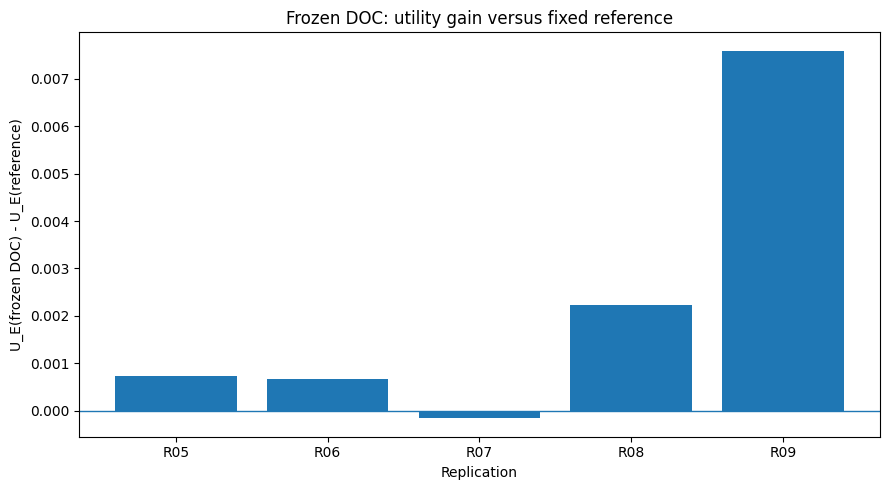

In [19]:
fig,ax=plt.subplots(
    figsize=(9,5)
)

ax.axhline(
    0,
    linewidth=1
)

ax.bar(
    principal["replication"],
    principal["gain_vs_reference"]
)

ax.set_title(
    "Frozen DOC: utility gain versus fixed reference"
)

ax.set_xlabel(
    "Replication"
)

ax.set_ylabel(
    "U_E(frozen DOC) - U_E(reference)"
)

plt.tight_layout()

fig.savefig(
    OUT/"gain_vs_reference.png",
    dpi=180
)

plt.show()

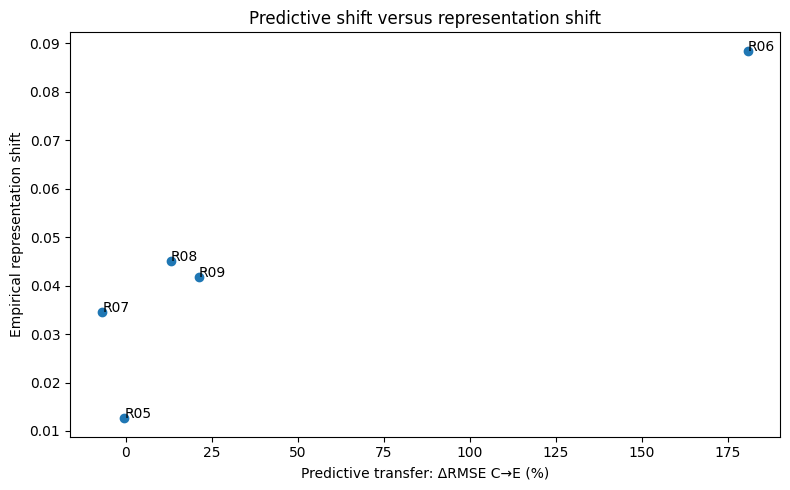

In [20]:
fig,ax=plt.subplots(
    figsize=(8,5)
)

ax.scatter(
    principal["delta_RMSE_pct"],
    principal["representation_shift_hat"]
)

for r in principal.itertuples(index=False):
    ax.annotate(
        r.replication,
        (
            r.delta_RMSE_pct,
            r.representation_shift_hat
        )
    )

ax.set_xlabel(
    "Predictive transfer: ΔRMSE C→E (%)"
)

ax.set_ylabel(
    "Empirical representation shift"
)

ax.set_title(
    "Predictive shift versus representation shift"
)

plt.tight_layout()

fig.savefig(
    OUT/"predictive_vs_representation_shift.png",
    dpi=180
)

plt.show()

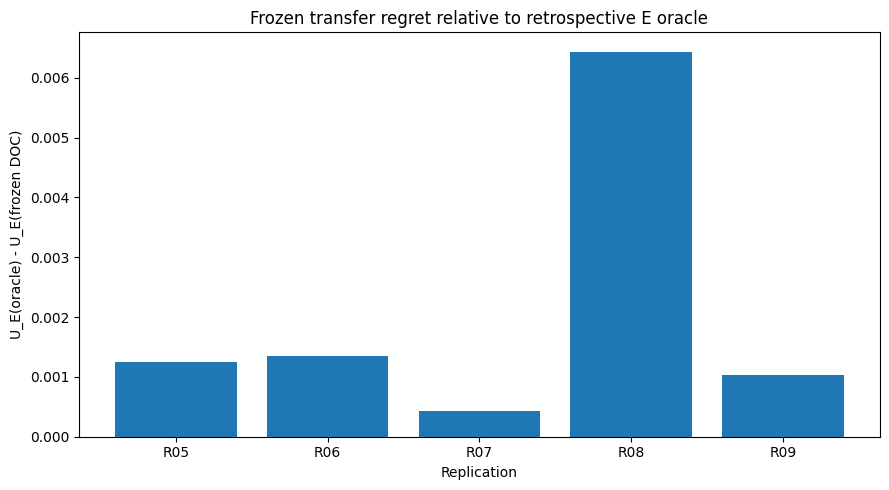

In [21]:
fig,ax=plt.subplots(
    figsize=(9,5)
)

ax.bar(
    principal["replication"],
    principal["transfer_regret"]
)

ax.set_title(
    "Frozen transfer regret relative to retrospective E oracle"
)

ax.set_xlabel(
    "Replication"
)

ax.set_ylabel(
    "U_E(oracle) - U_E(frozen DOC)"
)

plt.tight_layout()

fig.savefig(
    OUT/"frozen_transfer_regret.png",
    dpi=180
)

plt.show()

In [22]:
if (OUT/"runtime_progress.csv").exists():
    rt=pd.read_csv(
        OUT/"runtime_progress.csv"
    )

    display(rt.tail())

    if len(rt):
        last=rt.iloc[-1]

        print(
            "Branch wall time (h):",
            round(
                last["wall_elapsed_s"]/3600,
                2
            )
        )

        print(
            "Mean branch time (min):",
            round(
                last["mean_branch_s"]/60,
                2
            )
        )

zip_out=ROOT/"outputs_fame_gpu_04b_v4.zip"

with zipfile.ZipFile(
    zip_out,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(
                p,
                arcname=f"outputs_fame_gpu_04b_v4/{p.name}"
            )

print("ZIP criado:",zip_out.resolve())
print("Envie outputs_fame_gpu_04b_v4.zip.")

,completed,total,wall_elapsed_s,mean_branch_s,eta_s,workers
84,85,89,5891.182480,378.218667,252.145778,6
85,86,89,5910.784460,378.798037,189.399018,6
86,87,89,5914.319400,380.029348,126.676449,6
87,88,89,5925.151165,380.359437,63.393239,6
88,89,89,5953.623517,380.783939,0.000000,6


Branch wall time (h): 1.65
Mean branch time (min): 6.35
ZIP criado: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_04b_v4.zip
Envie outputs_fame_gpu_04b_v4.zip.
